# 🚀 Модуль 12. Урок 1. Концепция AI-агентов: ReAct, вызов инструментов (Tool Calling) и память

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_12_ai_agents/lesson_01_agentic_workflows_concept.ipynb)

## 📌 Бизнес-контекст и методология
Обычная языковая модель — это статический генератор текста.
**AI-агент (Agentic Workflow)** — это автономная система, обладающая:
1. **Планированием (Reasoning / Thought):** декомпозиция сложной бизнес-задачи на подцели
2. **Инструментами (Action / Tools):** выполнение SQL-запросов, запуск Python-кода, чтение API
3. **Наблюдением (Observation):** анализ результата работы инструмента
4. **Рефлексией (Verification):** проверка корректности и исправление ошибок (ReAct цикл)

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Итерационный цикл ReAct агента
Смоделируем агентский цикл выполнения аналитического поручения: *«Посчитай выручку по топ-3 категориям и сохрани график»*.

In [2]:
# Демонстрация: Симуляция шагов ReAct цикла
agent_trace = pd.DataFrame({
    'Шаг': [1, 2, 3, 4, 5],
    'Фаза ReAct': ['Thought', 'Action', 'Observation', 'Thought', 'Final Answer'],
    'Содержание': [
        'Нужно запросить схему таблиц для поиска категорий',
        'execute_sql("PRAGMA table_info(products);")',
        'Таблица содержит поля product_id, category, price',
        'Пишу SQL запрос с GROUP BY category и расчетом суммы',
        'Выручка рассчитана: Electronics ($740k), Fashion ($720k), Beauty ($603k)'
    ]
})
display(agent_trace)

,Шаг,Фаза ReAct,Содержание
0,1,Thought,Нужно запросить схему таблиц для поиска категорий
1,2,Action,"execute_sql(""PRAGMA table_info(products);"")"
2,3,Observation,"Таблица содержит поля product_id, category, price"
3,4,Thought,Пишу SQL запрос с GROUP BY category и расчетом...
4,5,Final Answer,"Выручка рассчитана: Electronics ($740k), Fashi..."


## 📊 Визуализация бизнес-кейса: Архитектура автономного цикла ReAct
Построим блок-схему взаимодействия компонентов аналитического агента.

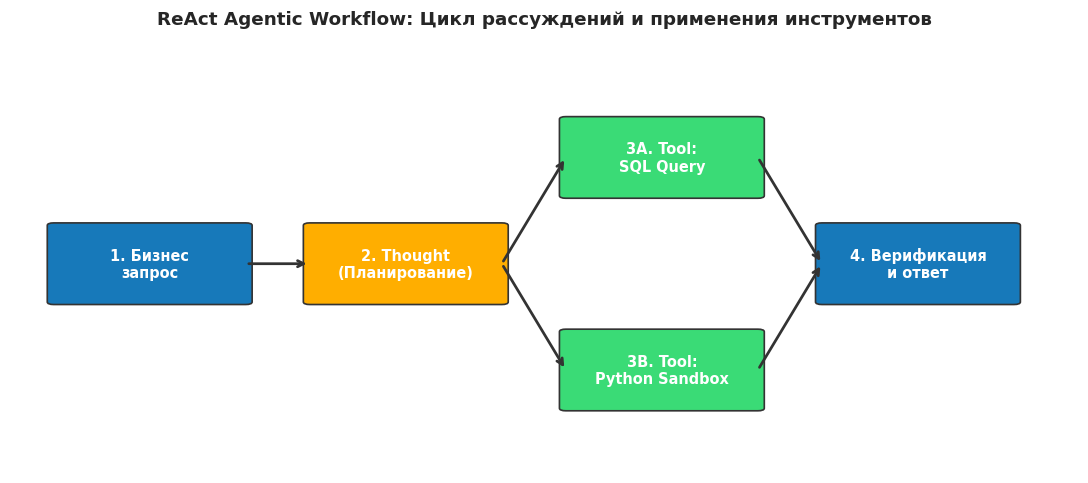

In [3]:
# Визуализация агентского цикла
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=110)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

def draw_agent_box(x, y, text, color, w=18, h=18):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6", 
                                  facecolor=color, edgecolor="#333333", linewidth=1.1)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, color='white', fontweight='bold', 
            fontsize=9.5, ha='center', va='center')

draw_agent_box(4, 40, "1. Бизнес\nзапрос", PRIMARY)
draw_agent_box(28, 40, "2. Thought\n(Планирование)", WARNING)
draw_agent_box(52, 65, "3A. Tool:\nSQL Query", SUCCESS)
draw_agent_box(52, 15, "3B. Tool:\nPython Sandbox", SUCCESS)
draw_agent_box(76, 40, "4. Верификация\nи ответ", PRIMARY)

# Стрелки цикла
ax.annotate("", xy=(28, 49), xytext=(22, 49), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.8))
ax.annotate("", xy=(52, 74), xytext=(46, 49), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.8))
ax.annotate("", xy=(52, 24), xytext=(46, 49), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.8))
ax.annotate("", xy=(76, 49), xytext=(70, 74), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.8))
ax.annotate("", xy=(76, 49), xytext=(70, 24), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.8))

ax.set_title("ReAct Agentic Workflow: Цикл рассуждений и применения инструментов", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Количество шагов агента
Проверьте количество шагов, зафиксированных в трейсе выполнения `agent_trace`.

In [4]:
### ВАШ КОД ЗДЕСЬ
steps_count = len(agent_trace)
print(f"Всего шагов в трейсе: {steps_count}")

assert steps_count == 5, "Трейс должен содержать 5 шагов"
print("✅ Тест успешно пройден: логика ReAct цикла подтверждена!")

Всего шагов в трейсе: 5
✅ Тест успешно пройден: логика ReAct цикла подтверждена!


### 💡 Защита от зацикливания агента (Loop Guard)
Всегда задавайте параметр `max_iterations = 10`. Если агент не может решить задачу за 10 шагов, он обязан прервать цикл и запросить уточнение у человека-аналитика.